In [2]:
# ==========================================
# 0. MONTAR GOOGLE DRIVE E INSTALAR DEPENDENCIAS
# ==========================================
from google.colab import drive
import os
import json
import orjson
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Configuración estética de gráficas
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# Ruta de tu dataset aplanado (el que solo tiene los 2.4M con médico)
archivo_jsonl = '/content/drive/MyDrive/TFG/data/medication_request_dataset_full.jsonl'

print("⏳ Cargando datos en Pandas (filtrando registros con médico)...")

⏳ Cargando datos en Pandas (filtrando registros con médico)...


In [23]:
registros = []
# Leemos el archivo completo
with open(archivo_jsonl, 'rt', encoding='utf-8') as f:
    for linea in f:
        try:
            data = json.loads(linea.strip())
            if data.get('order_provider_id'):  # Nos quedamos solo con los que tienen médico
                registros.append({
                    'provider_id': data.get('order_provider_id'),
                    'patient_id': data.get('patient_id'),
                    'encounter_id': data.get('encounter_id'),
                    'service_type': data.get('encounter_service_type', 'Desconocido'),
                    'medication': data.get('medication_name', 'Desconocido'),
                    'fue_administrado': data.get('fue_administrado', False),
                    'route_code': data.get('route_code', 'Desconocido'),
                    'diagnoses': data.get('encounter_diagnoses', 'No diagnosis recorded')
                })
        except json.JSONDecodeError:
            continue

df = pd.DataFrame(registros)
print(f"✅ Dataset cargado con éxito. Total de registros analizados: {len(df):,}")

✅ Dataset cargado con éxito. Total de registros analizados: 2,397,213


# 1. DISTRIBUCIÓN POR PROFESIONALES

Buscamos saber cuántos médicos únicos tenemos en total y cuántas recetas ha emitido cada uno.

Es importante porque nos ayuda a ver si hay médicos que recetan muchísimo (outliers) frente a otros que recetan poco.


--- 1. ANÁLISIS DE PROFESIONALES ---
Total de profesionales únicos: 7,697
Top 5 médicos con más prescripciones:
provider_id
P02M1N    12595
P73F56    12296
P15IX4    11992
P41USH    11440
P43RKP     8912
Name: count, dtype: int64


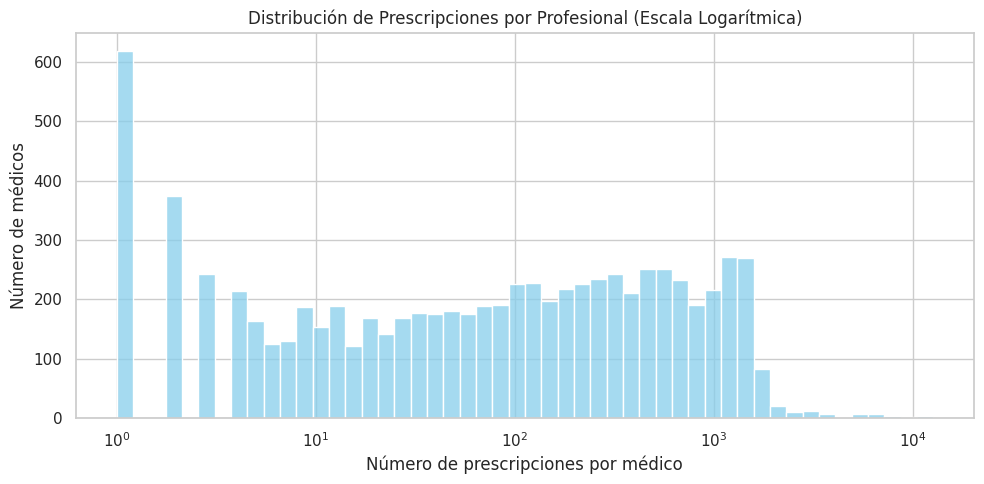

In [29]:
# ==========================================
# 1. Distribución por Profesionales
# ==========================================
print("\n--- 1. ANÁLISIS DE PROFESIONALES ---")
total_profesionales = df['provider_id'].nunique()
rx_por_profesional = df['provider_id'].value_counts()
print(f"Total de profesionales únicos: {total_profesionales:,}")
print("Top 5 médicos con más prescripciones:")
print(rx_por_profesional.head(5))

plt.figure(figsize=(10, 5))
sns.histplot(rx_por_profesional, bins=50, log_scale=True, color='skyblue')
plt.title('Distribución de Prescripciones por Profesional (Escala Logarítmica)')
plt.xlabel('Número de prescripciones por médico')
plt.ylabel('Número de médicos')
plt.show()

Asimetría Extrema: La gran mayoría de los médicos se concentran en un volumen moderado-bajo de prescripciones, mientras que unos pocos alcanzan hasta 12,000 registros.

El fenómeno de 1-2 recetas: El pico inicial de más de 600 médicos con una sola prescripción sugiere la presencia de personal en rotaciones clínicas muy breves (como residentes de guardia) o artefactos de cruce en el sistema que debemos documentar.

Para entrenar los modelos de IA, convendrá evaluar si filtramos a los médicos con un volumen extremadamente bajo (ej. menos de 5 recetas), ya que un modelo predictivo aprende mal de entidades con una sola muestra.


--- DETALLE DE MÉDICOS CON BAJO VOLUMEN ---
Cantidad de médicos según su número exacto de recetas (de 1 a 20):
count
1     618
2     374
3     242
4     214
5     163
6     125
7     129
8      99
9      88
10     76
Name: count, dtype: int64


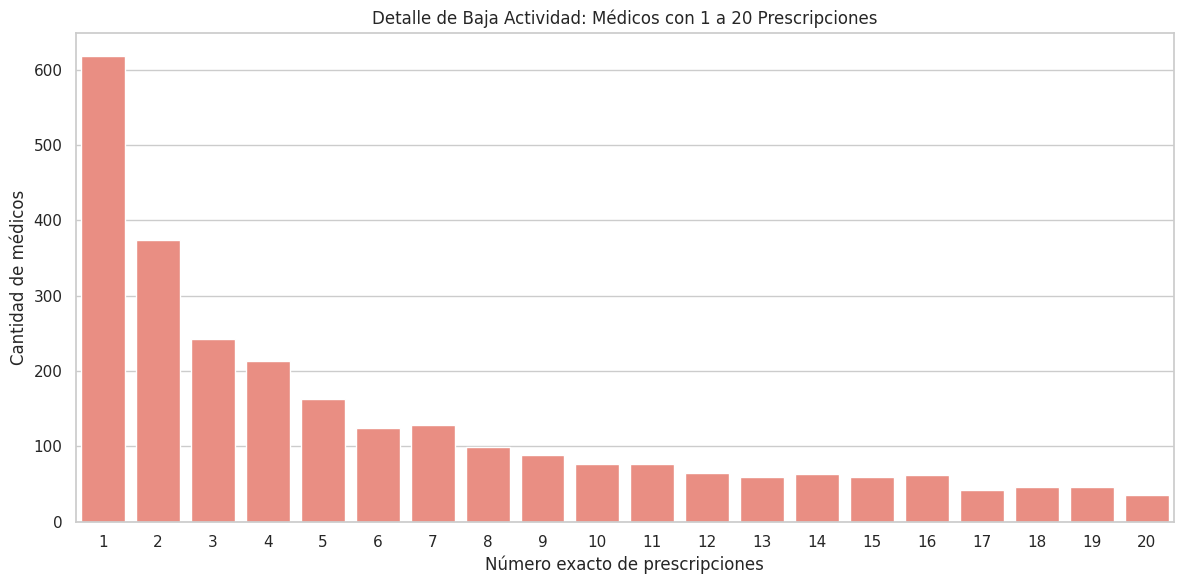

In [30]:
# ==========================================
# 1. ZOOM: Detalle de médicos con baja actividad (1 a 20 prescripciones)
# ==========================================
print("\n--- DETALLE DE MÉDICOS CON BAJO VOLUMEN ---")
rx_por_profesional = df['provider_id'].value_counts()

# Filtramos solo los médicos que tienen 20 o menos prescripciones
bajos_recursos = rx_por_profesional[rx_por_profesional <= 20]

# Mostramos cuántos médicos hay exactamente para 1 y 2 recetas
conteo_exacto = bajos_recursos.value_counts().sort_index()
print("Cantidad de médicos según su número exacto de recetas (de 1 a 20):")
print(conteo_exacto.head(10))

plt.figure(figsize=(12, 6))
# Gráfico de barras exacto para ver el desglose individual en este rango bajo
sns.countplot(x=bajos_recursos, color='salmon')
plt.title('Detalle de Baja Actividad: Médicos con 1 a 20 Prescripciones')
plt.xlabel('Número exacto de prescripciones')
plt.ylabel('Cantidad de médicos')
plt.show()

El análisis de detalle de la baja actividad profesional confirma una fuerte concentración de médicos con un volumen mínimo de registros, destacando de forma sobresaliente 618 profesionales con exactamente una prescripción y 374 con dos.

Este fenómeno refleja la intervención de personal clínico en rotaciones breves, guardias puntuales o posibles artefactos de asignación en el sistema, lo que aconseja establecer un umbral de filtrado previo en el preprocesamiento de los datos para evitar sesgos y dotar a los futuros modelos de aprendizaje automático de una base más robusta y fiable.

# 2. DISTRIBUCIÓN POR ESPECIALIDADES

Buscamos ver cuántas especialidades clínicas distintas existen en el hospital y cuántas prescripciones acumula cada una.


--- 2. ANÁLISIS DE ESPECIALIDADES ---
Total de especialidades únicas: 19
service_type
MED      993866
CMED     279441
SURG     229184
OMED     179836
CSURG    112882
ORTHO    105676
NMED     102251
NSURG     90519
VSURG     71141
OBS       54640
TRAUM     51755
PSYCH     32891
TSURG     31941
GYN       21856
GU        20776
PSURG     13632
ENT        4670
EYE         176
DENT         80
Name: count, dtype: int64


/tmp/ipykernel_2138/46393505.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rx_por_especialidad.index, y=rx_por_especialidad.values, palette='viridis')


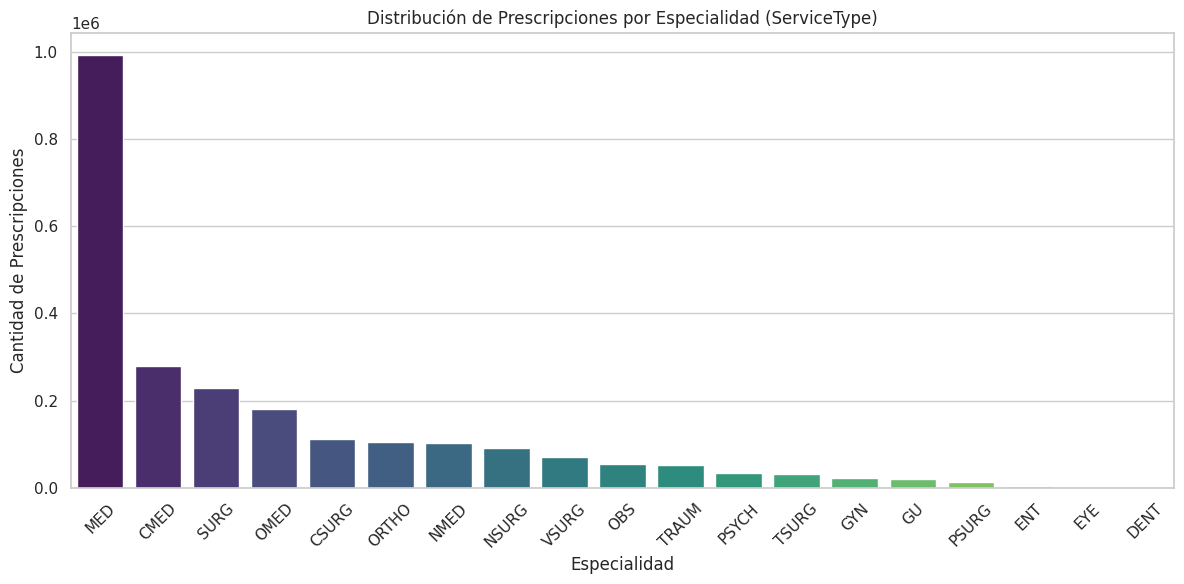

In [31]:
# ==========================================
# 2. Distribución por Especialidades (ServiceType)
# ==========================================
print("\n--- 2. ANÁLISIS DE ESPECIALIDADES ---")
rx_por_especialidad = df['service_type'].value_counts()
print(f"Total de especialidades únicas: {df['service_type'].nunique()}")
print(rx_por_especialidad)

plt.figure(figsize=(12, 6))
sns.barplot(x=rx_por_especialidad.index, y=rx_por_especialidad.values, palette='viridis')
plt.title('Distribución de Prescripciones por Especialidad (ServiceType)')
plt.xlabel('Especialidad')
plt.ylabel('Cantidad de Prescripciones')
plt.xticks(rotation=45)
plt.show()

La distribución de prescripciones entre las 19 especialidades evidencia un claro predominio de los servicios de Medicina General/Interna (MED), que concentran casi un millón de recetas, seguidos a distancia por especialidades médicas y quirúrgicas generales (CMED, SURG, OMED), mientras que departamentos muy específicos como EYE o DENT registran valores casi testimoniales.


 Este desequilibrio estructural representa un desafío analítico importante para los futuros modelos de Machine Learning, ya que las clases mayoritarias eclipsarán a las minoritarias si no se aplican técnicas de ponderación o normalización adecuadas.

# 3. RELACIÓN ENTRE MÉDICOS Y ESPECIALISTAS

Buscamos calcular en cuántas especialidades diferentes prescribe cada médico (ej. el médico A solo prescribe en 1 especialidad, pero el médico B prescribe en 4).

Es clave para detectar anomalías o fraude en el futuro, ya que si un médico de una especialidad empieza a recetar fármacos propios de otra completamente ajena, salta la alerta.


--- 3. RELACIÓN MÉDICOS Y ESPECIALIDADES ---
Número de médicos según la cantidad de especialidades en las que prescriben (Ordenado):
service_type
1      719
2      475
3      348
4      303
5      281
6      231
7      217
8      200
9      195
10     200
11     236
12     285
13     317
14     391
15     536
16     971
17    1627
18     157
19       8
Name: count, dtype: int64


/tmp/ipykernel_2138/979419342.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medico_especialidades.index, y=medico_especialidades.values, palette='Blues_d')


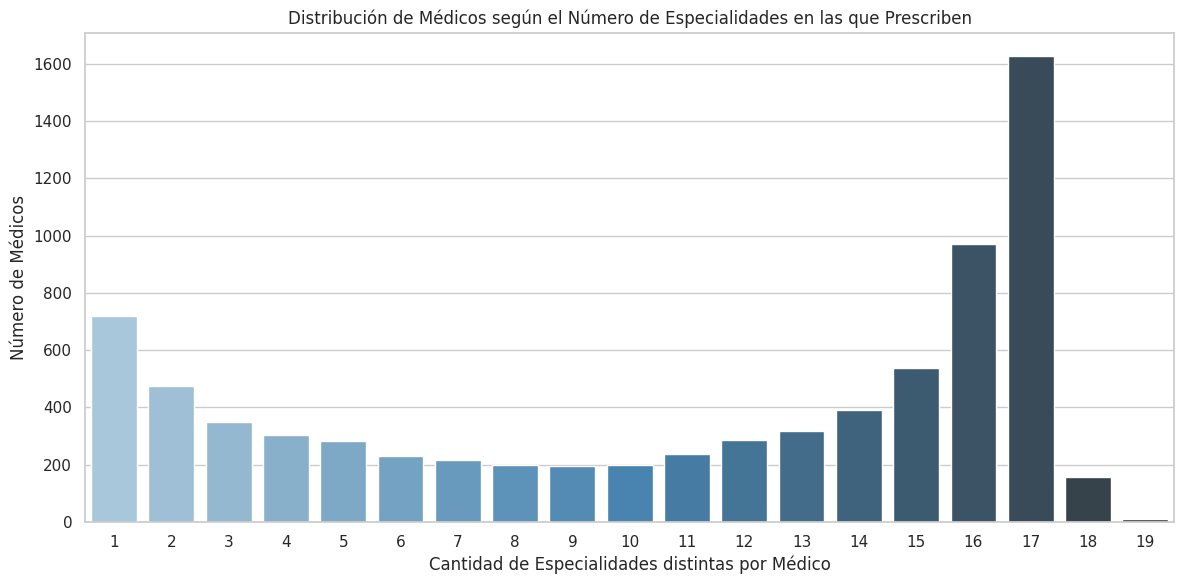

In [32]:
# ==========================================
# 3. RELACIÓN: MÉDICOS VS ESPECIALIDADES
# ==========================================
print("\n--- 3. RELACIÓN MÉDICOS Y ESPECIALIDADES ---")
# Calculamos y ordenamos estrictamente del 1 al 19
medico_especialidades = df.groupby('provider_id')['service_type'].nunique().value_counts().sort_index()
print("Número de médicos según la cantidad de especialidades en las que prescriben (Ordenado):")
print(medico_especialidades)

# Gráfico mejorado para visualizarlo claramente
plt.figure(figsize=(12, 6))
sns.barplot(x=medico_especialidades.index, y=medico_especialidades.values, palette='Blues_d')
plt.title('Distribución de Médicos según el Número de Especialidades en las que Prescriben')
plt.xlabel('Cantidad de Especialidades distintas por Médico')
plt.ylabel('Número de Médicos')
plt.show()

La gran mayoría de los profesionales sanitarios de la muestra presentan un perfil marcadamente transversal o multidisciplinar, abarcando prescripciones en un amplio abanico de especialidades (con un pico destacado de más de 1.600 médicos que operan en 17 áreas distintas), frente a un grupo más reducido de 719 profesionales que limitan su actividad estrictamente a una única especialidad.

Este comportamiento refleja la alta rotación y polivalencia del personal clínico en el entorno hospitalario del dataset, lo cual subraya que los algoritmos de detección de fraude y anomalías no deben penalizar por defecto la multidisciplinariedad, sino aprender a distinguir entre la movilidad asistencial legítima y los patrones atípicos de prescripción cruzada.

# 4. DISTRIBUCIÓN DE PRESCRIPCIONES POR PACIENTES

Analizamos cuántos pacientes tenemos y cuántas prescripciones tiene asociadas cada uno.


--- 4. ANÁLISIS DE PACIENTES ---
Total de pacientes únicos: 152,969


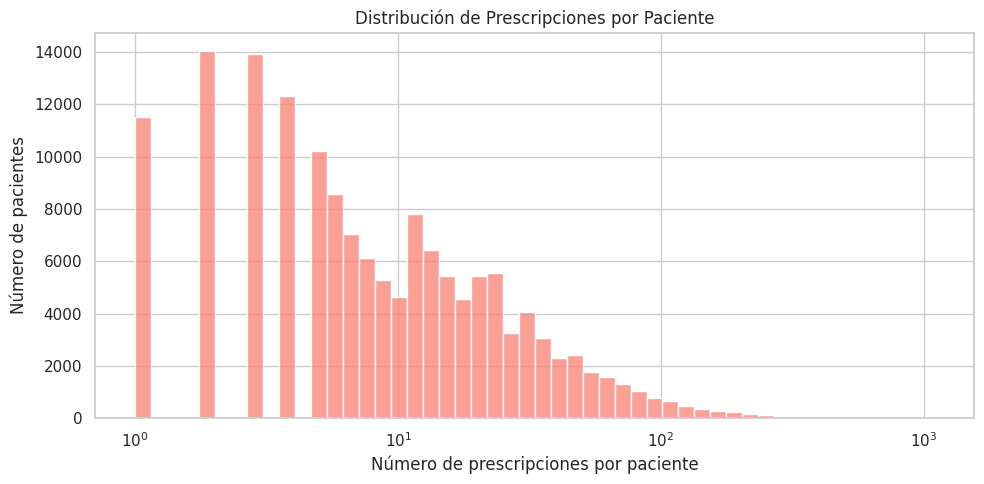

In [33]:
# ==========================================
# 4. Distribución por Pacientes
# ==========================================
print("\n--- 4. ANÁLISIS DE PACIENTES ---")
total_pacientes = df['patient_id'].nunique()
rx_por_paciente = df['patient_id'].value_counts()
print(f"Total de pacientes únicos: {total_pacientes:,}")

plt.figure(figsize=(10, 5))
sns.histplot(rx_por_paciente, bins=50, log_scale=True, color='salmon')
plt.title('Distribución de Prescripciones por Paciente')
plt.xlabel('Número de prescripciones por paciente')
plt.ylabel('Número de pacientes')
plt.show()

La gran mayoría de los pacientes tienen pocas recetas porque corresponden a visitas rápidas de urgencias o consultas ambulatorias, mientras que un grupo menor acumula decenas de prescripciones por ingresos largos o cronicidad.

 Es una variabilidad totalmente lógica que el modelo de IA deberá aprender a manejar para distinguir entre un paciente crónico real y una anomalía de prescripción

# 5. PRESCRIPCIONES POR MEDICAMENTO
Buscamos cuántos medicamentos están prescritos y cuántas veces


--- 5. ANÁLISIS DE MEDICAMENTOS ---
Total de medicamentos únicos: 4,927
Top 10 medicamentos más prescritos:
medication
Insulin                        106545
Sodium Chloride 0.9%  Flush     91754
Acetaminophen                   78169
IV Fluid / Mix: 50 mL Bag       65497
Heparin                         54843
Furosemide                      53202
Docusate Sodium                 50287
Potassium Chloride              49353
HYDROmorphone (Dilaudid)        46794
Metoprolol Tartrate             43033
Name: count, dtype: int64


/tmp/ipykernel_2138/2857397732.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_meds.values, y=top_10_meds.index, palette='crest')


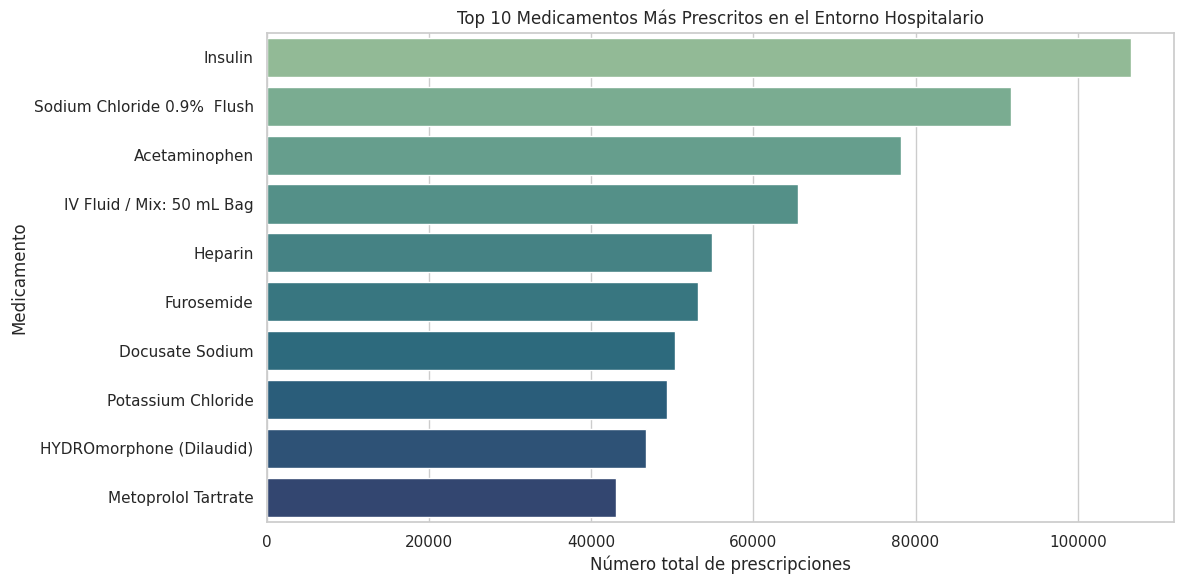

In [28]:
# ==========================================
# 5. Distribución por Medicamento
# ==========================================
print("\n--- 5. ANÁLISIS DE MEDICAMENTOS ---")
total_medicamentos = df['medication'].nunique()
rx_por_medicamento = df['medication'].value_counts()
print(f"Total de medicamentos únicos: {total_medicamentos:,}")
print("Top 10 medicamentos más prescritos:")
print(rx_por_medicamento.head(10))

plt.figure(figsize=(12, 6))
top_10_meds = rx_por_medicamento.head(10)

# Gráfico de barras horizontales para que los nombres de los fármacos se lean perfectamente
sns.barplot(x=top_10_meds.values, y=top_10_meds.index, palette='crest')
plt.title('Top 10 Medicamentos Más Prescritos en el Entorno Hospitalario')
plt.xlabel('Número total de prescripciones')
plt.ylabel('Medicamento')
plt.show()

El análisis del catálogo farmacológico revela un predominio absoluto de tratamientos de soporte vital básico, control glucémico y gestión de fluidos (liderados por la insulina y soluciones salinas), lo cual refleja fielmente la actividad diaria de hospitalización y cuidados agudos.

Esta distribución equilibrada de los fármacos más habituales proporciona una línea base sólida para que el sistema de inteligencia artificial detecte eficazmente patrones de prescripción anómalos o desviaciones en la práctica clínica habitual.

# 6. POLIMEDICACIÓN ANTE LA DIVERSIDAD MÉDICA POR PACIENTE



--- 6. ANÁLISIS DE FRAGMENTACIÓN ASISTENCIAL ---
       total_recetas  medicamentos_unicos  medicos_distintos
count  152969.000000        152969.000000      152969.000000
mean       15.671234            10.744268          15.396087
std        27.383348            12.093229          25.789209
min         1.000000             1.000000           1.000000
25%         3.000000             3.000000           3.000000
50%         7.000000             7.000000           7.000000
75%        17.000000            14.000000          17.000000
max      1094.000000           177.000000         848.000000


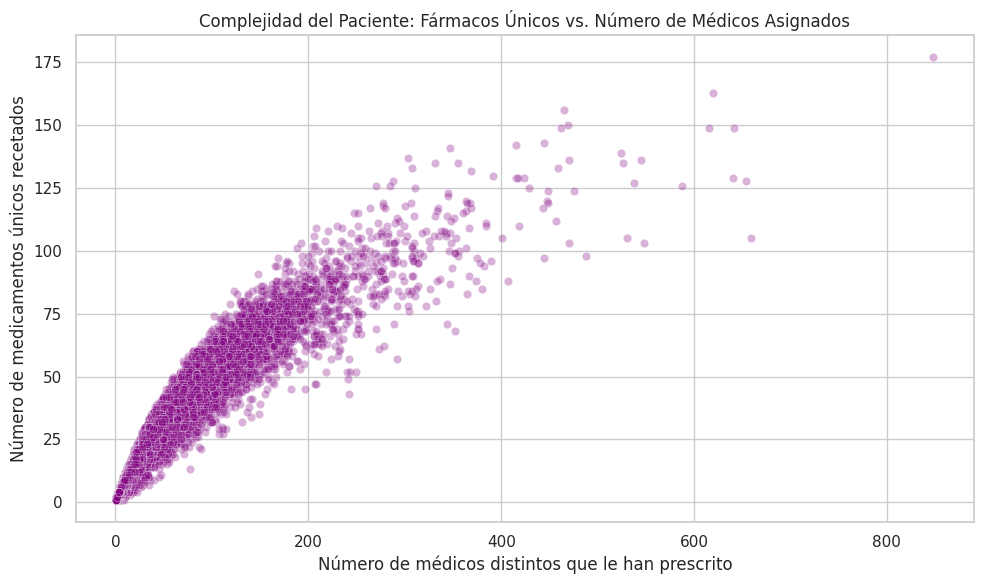

In [34]:
# ==========================================
# 6. Polimedicación vs Diversidad Médica por Paciente
# ==========================================
print("\n--- 6. ANÁLISIS DE FRAGMENTACIÓN ASISTENCIAL ---")
resumen_pacientes = df.groupby('patient_id').agg(
    total_recetas=('medication', 'count'),
    medicamentos_unicos=('medication', 'nunique'),
    medicos_distintos=('provider_id', 'nunique')
).reset_index()

print(resumen_pacientes[['total_recetas', 'medicamentos_unicos', 'medicos_distintos']].describe())

# Gráfico de dispersión (Scatter plot) para ver anomalías visuales
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=resumen_pacientes,
    x='medicos_distintos',
    y='medicamentos_unicos',
    alpha=0.3,
    color='purple'
)
plt.title('Complejidad del Paciente: Fármacos Únicos vs. Número de Médicos Asignados')
plt.xlabel('Número de médicos distintos que le han prescrito')
plt.ylabel('Número de medicamentos únicos recetados')
plt.show()

El gráfico de fragmentación demuestra que existe una relación directa entre el número de médicos que tratan a un paciente y la cantidad de medicamentos únicos que recibe: cuantos más especialistas intervienen, mayor es la polimedicación inicial. No obstante, la curva revela un límite biológico y clínico evidente (que se estabiliza alrededor de los 150-175 fármacos únicos).

Esto significa que, por muy alta que sea la rotación o la cantidad de médicos distintos que atiendan a un paciente crónico, la variedad de medicamentos se satura. Para el TFG, este comportamiento es clave, ya que los algoritmos de IA podrán usar esta "frontera" para detectar casos anómalos o sospechosos (por ejemplo, pacientes que rompan esta lógica acumulando una variedad ilimitada de fármacos sin justificación clínica).

# 7. TASA DE ADMINISTRACIÓN POR ESPECIALIDAD

--- 7. AUDITORÍA: TASA DE ADMINISTRACIÓN POR ESPECIALIDAD ---
service_type  total_recetas  administradas  porcentaje_administrado
         EYE            176             82                46.590909
        DENT             80             33                41.250000
       PSURG          13632           5520                40.492958
       ORTHO         105676          42309                40.036527
         GYN          21856           8345                38.181735
          GU          20776           7566                36.417020
        CMED         279441         100218                35.863742
         MED         993866         354391                35.657825
         ENT           4670           1639                35.096360
        SURG         229184          77329                33.741012
       TSURG          31941          10473                32.788579
       VSURG          71141          22762                31.995614
       NSURG          90519          28212            

/tmp/ipykernel_2138/2308783105.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tasa_admin_esp, x='service_type', y='porcentaje_administrado', palette='magma')


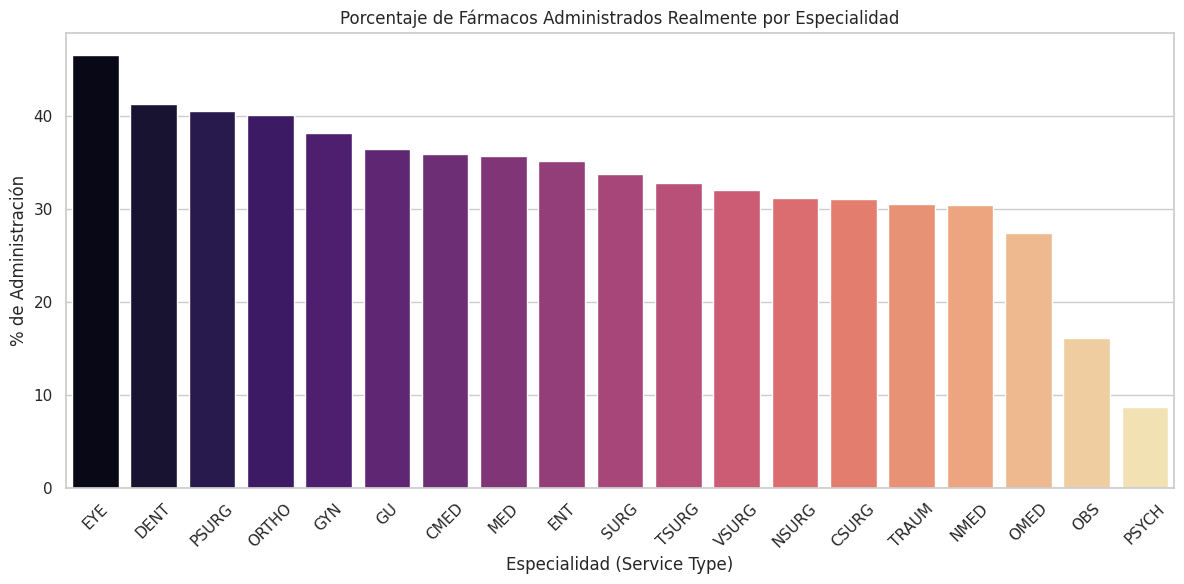

In [40]:
# ==============================================================================
# 7. TASA DE ADMINISTRACIÓN POR ESPECIALIDAD
# ==============================================================================
print("--- 7. AUDITORÍA: TASA DE ADMINISTRACIÓN POR ESPECIALIDAD ---")
tasa_admin_esp = df.groupby('service_type')['fue_administrado'].agg(
    total_recetas='count', administradas='sum'
).reset_index()

tasa_admin_esp['porcentaje_administrado'] = (tasa_admin_esp['administradas'] / tasa_admin_esp['total_recetas']) * 100
tasa_admin_esp = tasa_admin_esp.sort_values(by='porcentaje_administrado', ascending=False)

print(tasa_admin_esp.to_string(index=False))

# Gráfico visual para las especialidades
plt.figure(figsize=(12, 6))
sns.barplot(data=tasa_admin_esp, x='service_type', y='porcentaje_administrado', palette='magma')
plt.title('Porcentaje de Fármacos Administrados Realmente por Especialidad')
plt.xlabel('Especialidad (Service Type)')
plt.ylabel('% de Administración')
plt.xticks(rotation=45)
plt.show()

El modelo aprenderá en qué departamentos se administra más o menos medicación gracias a la bandera fue_administrado, que registra si la enfermería aplicó físicamente el fármaco en planta.

Así, la IA comprenderá que las altas tasas en hospitalización responden a tratamientos directos, mientras que los bajos porcentajes en áreas como Psiquiatría u Obstetricia se deben a pautas de alta domiciliaria. Esto dota al sistema de una base de normalidad para evitar falsos positivos y detectar anomalías con precisión.

# 8. FÁRMACOS CON MAYOR Y MENOR TASA DE ADMINISTRACIÓN

In [39]:
# ==============================================================================
# 8. FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN
# ==============================================================================
print("--- 8. AUDITORÍA: FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN ---")
tasa_med = df.groupby('medication').agg(
    total_recetas=('fue_administrado', 'count'),
    administradas=('fue_administrado', 'sum')
).reset_index()

tasa_med['porcentaje_administrado'] = (tasa_med['administradas'] / tasa_med['total_recetas']) * 100

# Filtramos fármacos con relevancia estadística (más de 100 recetas)
tasa_med_relevantes = tasa_med[tasa_med['total_recetas'] > 100]

print("Top 5 Fármacos con MAYOR tasa de administración:")
print(tasa_med_relevantes.sort_values(by='porcentaje_administrado', ascending=False).head(5).to_string(index=False))

print("\nTop 5 Fármacos con MENOR tasa de administración (Posibles cancelaciones/alertas):")
print(tasa_med_relevantes.sort_values(by='porcentaje_administrado', ascending=True).head(5).to_string(index=False))

--- 8. AUDITORÍA: FÁRMACOS CON MENOR Y MAYOR TASA DE ADMINISTRACIÓN ---
Top 5 Fármacos con MAYOR tasa de administración:
                                    medication  total_recetas  administradas  porcentaje_administrado
                                     rifAXIMin            142            134                94.366197
         Neostigmine (CVICU Reversal Protocol)            109            102                93.577982
                           Esomeprazole sodium            137            128                93.430657
IV Fluid / Mix: 2 g / 100 mL Dextrose (iso-os)           1295           1186                91.583012
                                 DULoxetine DR            145            132                91.034483

Top 5 Fármacos con MENOR tasa de administración (Posibles cancelaciones/alertas):
                          medication  total_recetas  administradas  porcentaje_administrado
                         Ziprasidone            108              0                      0.0


El estudio detallado a nivel de fármaco identifica elementos con una tasa de administración intrahospitalaria nula (0,0 %), a pesar de contar con un volumen relevante de prescripciones (como analgésicos de liberación prolongada u optimizadores respiratorios).

 Este fenómeno se explica porque la bandera fue_administrado depende estrictamente de que la enfermería pinche o entregue el fármaco físicamente en la cama del hospital: los fármacos con menor probabilidad de marcarse como True suelen corresponder a recetas de alta para llevar a casa, inhaladores de uso personal (self-administration) o tratamientos condicionales (PRN o "según necesidad").

 Comprender que la probabilidad de que fue_administrado sea afirmativo depende directamente del tipo de medicamento permite que el modelo de aprendizaje automático aprenda las limitaciones operativas reales del entorno hospitalario y distinga con precisión entre una pauta domiciliaria legítima y una posible anomalía clínica.